<div align="center">

####
#### Máster Universitario en Ingeniería Biomédica y Salud Digital
#### Trabajo Fin de Máster
<br>

**Diseño y desarrollo de un modelo de Machine Learning para predicción de la propagación del Dengue**
<br><br>
</div>
<div align="left">
Realizado por: Carlos Lazzarino <br>
Dirigido por: Isabel Nepomuceno Chamorro

</div>


**Propósito del Notebook:**
Este documento presenta el *pipeline* para el diseño, entrenamiento y evaluación de modelos predictivos de Machine Learning aplicados a la propagación del Dengue en San Juan (Puerto Rico) e Iquitos (Perú), para la competición de DrivenData.

**Contenido:**
1. Configuración de entorno y carga de datos.
2. Preprocesamiento y *Feature Engineering*
3. Entrenamiento de modelos (*LightGBM*, *Support Vector Machines* y *Redes Neuronales* con Torch).
4. Generación de predicciones finales para la competición de DrivenData.

#Instalación de paquetes y carga de datos

## 1. Configuración de Entorno y Carga de Librerías

Es posible la ejecución en Google Colab, para garantizar la reproducibilidad y el correcto funcionamiento del entorno, es necesario:
*   Copiar los archivos de datos en bruto (`.csv`) en el directorio de trabajo.
*   Asegurar que el entorno de ejecución esté configurado en **R**.
*   Para el entrenamiento de Redes Neuronales, se recomienda cambiar el "Acelerador de hardware" a GPU (T4 o similar) en las opciones del entorno.

**Instalar y cargar librerias**

A continuación, se instalan y cargan las librerías necesarias. Utilizamos `data.table` para la manipulación eficiente de datos, `zoo` para la imputación de series temporales, y los paquetes específicos de modelado (`lightgbm`, `e1071`, y `rBayesianOptimization`). Para `torch`, utilizamos la implementación nativa de R `torch` junto con su *wrapper* `luz`.

In [1]:
# Instalación y carga de paquetes estadísticos y de Machine Learning clásico
# Esta sección asimismo revisa si ya están cargadas las librerias, en ocasiones algunas ya están instaladas en Colab

packages <- c("data.table", "lightgbm", "zoo", "rBayesianOptimization", "e1071")
packages_faltantes <- packages[!(packages %in% installed.packages()[,"Package"])]
if(length(packages_faltantes) > 0) {
  cat("Instalando paquetes faltantes:", paste(packages_faltantes, collapse=", "), "\n")
  install.packages(packages_faltantes)
} else {
  cat("Todos los paquetes ya están instalados.\n")
}
invisible(lapply(packages, library, character.only = TRUE))
cat("Todas las librerías están cargadas")


Instalando paquetes faltantes: lightgbm, zoo, rBayesianOptimization, e1071 


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘lhs’, ‘foreach’, ‘GPfit’, ‘proxy’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘zoo’


The following objects are masked from ‘package:data.table’:

    yearmon, yearqtr


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




Todas las librerías están cargadas

In [2]:
# Instalación y carga del entorno Torch para Redes Neuronales (creado por POSIT)

#Keras/Tensorflow falla ocasionalmente en algunos entornos R, dependiendo la versión, por lo que lo hice por separado y utilicé una librería nativa de R (Torch)
#Para keras, se utiliza reticulate que es una interfaz puente que permite ejecutar código Python dentro de una sesión de R y se instala keras3,
#Las versiones anteriores son obsoletas y podrían no correr en Colab. Esta instalación puede demorar unos 15-20 minutos.

if (!("torch" %in% installed.packages()[,"Package"])) {
  cat("Instalando el paquete base 'torch'...\n")
  install.packages("torch")
}
library(torch)

if (!torch_is_installed()) {
  cat("Descargando el motor C++ libtorch (esto se hace una sola vez y pesa ~1.5GB)...\n")
  install_torch()
}

if (!("luz" %in% installed.packages()[,"Package"])) {
  cat("Instalando 'luz' (es un wrapper estilo Keras para Torch)...\n")
  install.packages("luz")
}
library(luz)


Instalando el paquete base 'torch'...


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘coro’, ‘safetensors’




Instalando 'luz' (es un wrapper estilo Keras para Torch)...


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zeallot’




## 2. Carga de Datos

Los datos provienen del repositorio de la competición "Predict the Next Pandemic" de DrivenData. Contienen observaciones climáticas (NOAA) y satelitales para las ciudades de San Juan y Iquitos. Procedemos a cargar las variables predictoras (*features*) y las etiquetas (*labels*) de entrenamiento y prueba.

In [3]:
# En colab se requiere modificar el Path donde se encuentran los archivos en bruto en la carpeta del entorno

# Definir ruta base
DATA_PATH_INPUT <- "./input/"   #"../input/"
DATA_PATH_OUTPUT <- "./output/"    #"../output/

# Carga de datos
train_features <- fread(paste0(DATA_PATH_INPUT, "dengue_features_train.csv"))
train_labels <- fread(paste0(DATA_PATH_INPUT, "dengue_labels_train.csv"))
test_features <- fread(paste0(DATA_PATH_INPUT, "dengue_features_test.csv"))
submission_format <- fread(paste0(DATA_PATH_INPUT, "submission_format.csv"))

## 3. Preprocesamiento y Feature Engineering

Para garantizar que las series temporales no queden truncadas, se pre-procesan ambos conjuntos de datos de forma conjunta.

### 3.1. Unión e Imputación Inicial
Concatenamos temporalmente *Train* y *Test*. Luego, aplicamos técnicas de imputación direccional (*Last Observation Carried Forward* - LOCF y *Next Observation Carried Backward* - NOCB) para resolver los valores nulos provenientes de lecturas defectuosas.

In [4]:
# Unión de las features y labels de train
train_data <- merge(train_features, train_labels, by=c("city", "year", "weekofyear"))

# Se añade una columna vacía a test para poder concatenar todo
test_features[, total_cases := NA]
dataset <- rbindlist(list(train_data, test_features), use.names=TRUE, fill=TRUE)

cat("Datos combinados. Filas totales:", nrow(dataset), "\n")

# 3. Preprocesamiento (Imputación de los NA por LOCF Last Observation Carried Forward) -hay NA en el índice de vegetación en el database original-
setorder(dataset, city, year, weekofyear)

# Definimos las columnas numéricas ambientales
cols_climaticas <- setdiff(names(dataset), c("city", "year", "weekofyear", "week_start_date", "total_cases"))

# Imputamos arrastrando el último valor válido (LOCF) y luego el próximo (NOCB) por si hay nulos al inicio
dataset[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm=FALSE)), by=city, .SDcols=cols_climaticas]
dataset[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, fromLast=TRUE, na.rm=FALSE)), by=city, .SDcols=cols_climaticas]


Datos combinados. Filas totales: 1872 


### 3.2. Feature Engineering

Debido al ciclo de vida biológico del mosquito *Aedes aegypti*, el clima impacta la tasa de contagio con un retardo temporal. Para modelar esta latencia, se preparó una función que genera:
*   **Derivadas Clínicas:** Amplitud térmica e Índice de Vegetación (NDVI) promedio.
*   **Retardos Temporales (Lags):** Desplazamiento de 1 a 4 semanas hacia atrás.
*   **Deltas:** Tasa de cambio semanal para detectar alteraciones climáticas bruscas.
*   **Promedios Móviles:** Ventanas de 4 y 8 semanas para extraer tendencias estacionales acumulativas.

In [5]:
# Definición de función modular para Feature Engineering
engineer_dengue_features <- function(dt, cols_base) {

  # 1. Creación de métricas derivadas inmediatas
  # Crea una nueva columna llamada temp_rango (que corresponde a la amplitud térmica) y una que calcula el promedio para esa semana del Indice de Vegetación (ndvi) a partir de los 4 valores aportados en el dataset.
  dt[, temp_rango := station_max_temp_c - station_min_temp_c]
  dt[, ndvi_promedio := rowMeans(cbind(ndvi_ne, ndvi_nw, ndvi_se, ndvi_sw), na.rm=TRUE)]

  cols_a_laguear <- c(cols_base, "temp_rango", "ndvi_promedio")

  # 2. Retardos temporales (1 a 4 semanas)
  # Crea una copia del valor de esa variable pero desplazada 1 semana, 2, 3 y 4 semanas hacia atrás en el tiempo... tiempo del vector biológico
  for(l in 1:4) {
    dt[, paste0(cols_a_laguear, "_lag", l) := shift(.SD, l, type="lag"), by=city, .SDcols=cols_a_laguear]
  }

  # 3. Deltas semanales (respecto a la semana anterior)
  # Calcula la diferencia entre el valor y lag1
  for(col in cols_a_laguear) {
    dt[, paste0(col, "_delta1") := get(col) - get(paste0(col, "_lag1"))]
  }

  # 4. Promedios Móviles (Ventanas de 4 y 8 semanas)
  # Promedios Móviles (Tendencias de 4 y 8 semanas), son los promedios en ventana movil (para estudiar efecto acumulativo)
  for(col in cols_a_laguear) {
    dt[, paste0(col, "_rmean4") := frollmean(get(col), 4, align="right", na.rm=TRUE), by=city]
    dt[, paste0(col, "_rmean8") := frollmean(get(col), 8, align="right", na.rm=TRUE), by=city]
  }

  # 5. Segunda pasada de imputación para los NA generados en los saltos temporales
  # Se vuelve a aplicar LOCF y NOCB en todas las columnas que tengan NA
  # porque los promedios moviles, los lags y los delta generarán NA cuando el periodo de cálculo exceda el disponible en la base
  # Si hay NA va a fallar SVM
  cols_todas <- setdiff(names(dt), c("city", "year", "weekofyear", "week_start_date", "total_cases"))
  dt[, (cols_todas) := lapply(.SD, function(x) na.locf(na.locf(x, na.rm=FALSE), fromLast=TRUE, na.rm=FALSE)), by=city, .SDcols=cols_todas]

  # Eliminar week_start_date porque no es numérica y es redundante con la semana y el año que ya está presente
  dt[, week_start_date := NULL]

  return(dt)
}

# Ejecución de la función sobre el dataset
cat("Aplicando transformaciones temporales y estacionales...\n")
dataset <- engineer_dengue_features(dataset, cols_climaticas)
cat("Feature Engineering completado con éxito.\n")

Aplicando transformaciones temporales y estacionales...
Feature Engineering completado con éxito.


### 3.3. Separación Geográfica

Los biomas de San Juan (isla tropical costera) e Iquitos (selva amazónica) presentan comportamientos a priori distintos. Tras haber calculado los retardos, se separan los conjuntos de entrenamiento y prueba de manera aislada por ciudad.

In [6]:
# Separación Train / Test basada en la existencia de la variable objetivo
train_full <- dataset[!is.na(total_cases)]
test_full <- dataset[is.na(total_cases)]

# Segregación por bioma (Ciudad)
train_sj <- train_full[city == "sj"]
test_sj <- test_full[city == "sj"]

train_iq <- train_full[city == "iq"]
test_iq <- test_full[city == "iq"]

## 4. Modelo 1: Ensambles de Árboles (LightGBM)

En esta sección se preparan las matrices de datos específicas para el algoritmo LightGBM. Posteriormente, se inicia un proceso de Optimización Bayesiana para encontrar los mejores hiperparámetros, o bien, se cargan desde un archivo local si el proceso ya fue ejecutado previamente para ahorrar tiempo de cómputo.

In [7]:
# Preparar Matrices para LightGBM
features_lgb <- setdiff(names(train_sj), c("city", "year", "weekofyear", "total_cases"))

dtrain_sj <- lgb.Dataset(data = as.matrix(train_sj[, ..features_lgb]), label = train_sj$total_cases)
dtrain_iq <- lgb.Dataset(data = as.matrix(train_iq[, ..features_lgb]), label = train_iq$total_cases)

# Si ya se hizo antes toma el resultado con los mejores hiperparametros que se guardó en un .txt (para reducir tiempo de procesamiento más que nada)
archivo_params <- "mejores_parametros_lgb.txt"

if (file.exists(archivo_params)) {
  cat("¡Archivo de parámetros encontrado! Cargando configuración...\n")

  # Lee archivo y extrae valores
  lineas <- readLines(archivo_params)
  parametros <- list(
    objective = "regression_l1",
    metric = "mae",
    verbosity = -1,
    bagging_freq = 5
  )

  for(linea in lineas) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) {
      parametros[[partes[1]]] <- as.numeric(partes[2])
    }
  }
  if(!is.null(parametros$num_leaves)) parametros$num_leaves <- as.integer(parametros$num_leaves)

} else {

  # Si no está el archivo con los parámetros, inicia la optimización bayesiana....
  cat("No se encontró archivo de parámetros. Iniciando Optimización Bayesiana (este proceso tarda...)\n")

  # DEFINIR FUNCIÓN DE EVALUACIÓN
  # rBayesianOptimization siempre busca MAXIMIZAR. Como nuestro error (MAE) debe ser lo más bajo posible, buscamos que devuelva el MAE en negativo (-MAE).
  lgb_eval_fun <- function(learning_rate, num_leaves, feature_fraction, bagging_fraction) {

    pars <- list(
      objective = "regression_l1",
      metric = "mae",
      learning_rate = learning_rate,
      num_leaves = as.integer(num_leaves),
      feature_fraction = feature_fraction,
      bagging_fraction = bagging_fraction,
      bagging_freq = 5,
      verbosity = -1
    )

    # Usamos Validación Cruzada (CV) sobre San Juan para encontrar los mejores parámetros
    cv_modelo <- lgb.cv(
      params = pars,
      data = dtrain_sj,
      nrounds = 200,          # Límite de árboles
      nfold = 3,              # 3 particiones
      early_stopping_rounds = 20, # Frena si no mejora en 20 iteraciones
      showsd = FALSE
    )

    mejor_mae <- cv_modelo$best_score
    return(list(Score = -mejor_mae, Pred = 0))
  }

  # Definir los límites de busqueda (Bounds)
  limites <- list(
    learning_rate = c(0.01, 0.15),
    num_leaves = c(15L, 63L),  # L es porque es un rango de números enteros
    feature_fraction = c(0.5, 1.0),
    bagging_fraction = c(0.5, 1.0)
  )

  # EJECUCION DE LA OPTIMIZACION
  set.seed(42)
  opt_res <- BayesianOptimization(
    lgb_eval_fun,
    bounds = limites,
    init_points = 5,  # Puntos aleatorios iniciales
    n_iter = 15,      # numero de iteraciones de búsqueda
    acq = "ucb"
  )

  # Lista con los mejores parámetros
  mejores_pars <- opt_res$Best_Par
  parametros <- list(
    objective = "regression_l1",
    metric = "mae",
    learning_rate = mejores_pars["learning_rate"],
    num_leaves = as.integer(mejores_pars["num_leaves"]),
    feature_fraction = mejores_pars["feature_fraction"],
    bagging_fraction = mejores_pars["bagging_fraction"],
    bagging_freq = 5,
    verbosity = -1
  )

  # Guarda los resultados en un .txt para no volver a correrlo si ya se dispone de los resultados.
  cat("¡Optimización finalizada! Guardando los mejores parámetros en:", archivo_params, "\n")
  lineas_guardar <- c(
    paste0("learning_rate=", parametros$learning_rate),
    paste0("num_leaves=", parametros$num_leaves),
    paste0("feature_fraction=", parametros$feature_fraction),
    paste0("bagging_fraction=", parametros$bagging_fraction)
  )
  writeLines(lineas_guardar, archivo_params)
}

¡Archivo de parámetros encontrado! Cargando configuración...


### 4.1. Entrenamiento y evaluación interna (LightGBM)
Se procede al entrenamiento definitivo de los modelos para ambas ciudades utilizando los hiperparámetros óptimos, y se evalúa el Error Absoluto Medio (MAE) sobre el propio set de entrenamiento.

In [8]:

# Entrenamiento con los parámetros
cat("\nEntrenando los modelos con los parámetros óptimos...\n")

# NOTA: nrounds un poco más alto porque LightGBM es robusto si los parámetros son buenos
modelo_sj <- lgb.train(params = parametros, data = dtrain_sj, nrounds = 300)
modelo_iq <- lgb.train(params = parametros, data = dtrain_iq, nrounds = 300)

cat("¡Modelos entrenados! Evaluando métrica interna MAE estimada en Train...\n")
pred_train_sj <- predict(modelo_sj, as.matrix(train_sj[, ..features_lgb]))
mae_sj <- mean(abs(train_sj$total_cases - pred_train_sj))
cat(">> MAE Interno San Juan estimado:", round(mae_sj, 2), "\n")

pred_train_iq <- predict(modelo_iq, as.matrix(train_iq[, ..features_lgb]))
mae_iq <- mean(abs(train_iq$total_cases - pred_train_iq))
cat(">> MAE Interno Iquitos estimado:", round(mae_iq, 2), "\n")


Entrenando los modelos con los parámetros óptimos...
¡Modelos entrenados! Evaluando métrica interna MAE estimada en Train...
>> MAE Interno San Juan estimado: 9.42 
>> MAE Interno Iquitos estimado: 2.31 


### 4.2. Predicción y exportación (LightGBM)
Se generan las predicciones finales sobre el conjunto de prueba (`Test Set`). Debido a la naturaleza de los datos epidemiológicos, se aplica un control para evitar predicciones con valores de casos negativos antes de exportar el archivo CSV final.

In [9]:
# Predicción Final
cat("Generando predicciones finales...\n")
pred_test_sj <- round(predict(modelo_sj, as.matrix(test_sj[, ..features_lgb])))
pred_test_iq <- round(predict(modelo_iq, as.matrix(test_iq[, ..features_lgb])))

test_sj$total_cases <- ifelse(pred_test_sj < 0, 0, pred_test_sj)
test_iq$total_cases <- ifelse(pred_test_iq < 0, 0, pred_test_iq)

sub_lgb <- rbindlist(list(test_sj[, .(city, year, weekofyear, total_cases)],
                          test_iq[, .(city, year, weekofyear, total_cases)]))

Generando predicciones finales...


In [10]:
# Exportación
molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
molde[sub_lgb, total_cases := i.total_cases, on=.(city, year, weekofyear)]
molde[is.na(total_cases), total_cases := 0]

fwrite(molde, paste0(DATA_PATH_OUTPUT,"../output/submission_lightgbm.csv"))
cat("Archivo 'submission_lightgbm.csv' creado.\n")

Archivo 'submission_lightgbm.csv' creado.


## 5. Modelo 2: Máquinas de Vectores de Soporte (SVM)

Se implementa un segundo modelo basado en SVM para contrastar resultados. En este caso, se definen las columnas predictoras independientes y se realiza una optimización de parámetros mediante *Grid Search*, a menos que la configuración óptima ya haya sido guardada previamente.

In [11]:
cat("\n--- Entrenando Modelo 2: SVM ---\n")

archivo_params_svm <- "mejores_parametros_svm.txt"

# Definimos las columnas predictoras (excluyendo variables de control y objetivo)
features_model <- setdiff(names(train_sj), c("city", "year", "weekofyear", "total_cases"))

if (file.exists(archivo_params_svm)) {
  cat("¡Archivo de parámetros SVM encontrado! Cargando configuración guardada...\n")

  # Carga parámetros desde el archivo
  lineas_svm <- readLines(archivo_params_svm)
  p_svm <- list()
  for(linea in lineas_svm) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) p_svm[[partes[1]]] <- as.numeric(partes[2])
  }

  # Entrena modelo con parámetros guardados
  modelo_svm_sj <- svm(x = as.matrix(train_sj[, ..features_model]),
                       y = train_sj$total_cases,
                       type = "eps-regression", kernel = "radial", scale = TRUE,
                       cost = p_svm$cost_sj, gamma = p_svm$gamma_sj)

  modelo_svm_iq <- svm(x = as.matrix(train_iq[, ..features_model]),
                       y = train_iq$total_cases,
                       type = "eps-regression", kernel = "radial", scale = TRUE,
                       cost = p_svm$cost_iq, gamma = p_svm$gamma_iq)

  cat("Modelos San Juan e Iquitos entrenados con parámetros óptimos cargados.\n")

} else {
  cat("No se encontró archivo de parámetros SVM. Iniciando Grid Search (esto puede tardar)...\n")

  # Optimización para San Juan
  cat("Optimizando San Juan...\n")
  tune_sj <- tune(svm, train.x = as.matrix(train_sj[, ..features_model]), train.y = train_sj$total_cases,
                  type = "eps-regression", kernel = "radial", scale = TRUE,
                  ranges = list(cost = c(0.1, 1, 10, 50), gamma = c(0.01, 0.05, 0.1)))
  modelo_svm_sj <- tune_sj$best.model

  # Optimización para Iquitos
  cat("Optimizando Iquitos...\n")
  tune_iq <- tune(svm, train.x = as.matrix(train_iq[, ..features_model]), train.y = train_iq$total_cases,
                  type = "eps-regression", kernel = "radial", scale = TRUE,
                  ranges = list(cost = c(0.1, 1, 10, 50), gamma = c(0.01, 0.05, 0.1)))
  modelo_svm_iq <- tune_iq$best.model

  # Guarda resultados en .txt
  cat("Guardando mejores parámetros en:", archivo_params_svm, "\n")
  lineas_guardar_svm <- c(
    paste0("cost_sj=", modelo_svm_sj$cost),
    paste0("gamma_sj=", modelo_svm_sj$gamma),
    paste0("cost_iq=", modelo_svm_iq$cost),
    paste0("gamma_iq=", modelo_svm_iq$gamma)
  )
  writeLines(lineas_guardar_svm, archivo_params_svm)
}


--- Entrenando Modelo 2: SVM ---
¡Archivo de parámetros SVM encontrado! Cargando configuración guardada...
Modelos San Juan e Iquitos entrenados con parámetros óptimos cargados.


### 5.1. Evaluación y predicción (SVM)
De la misma manera que con el modelo anterior, se evalúa el MAE interno y se generan las predicciones finales con control de negativos para su posterior exportación.

In [12]:

# Evaluación interna MAE
pred_train_svm_sj <- predict(modelo_svm_sj, as.matrix(train_sj[, ..features_model]))
pred_train_svm_iq <- predict(modelo_svm_iq, as.matrix(train_iq[, ..features_model]))

cat("\n>> MAE Interno SVM San Juan:", round(mean(abs(train_sj$total_cases - pred_train_svm_sj)), 2), "\n")
cat(">> MAE Interno SVM Iquitos:", round(mean(abs(train_iq$total_cases - pred_train_svm_iq)), 2), "\n")

# Predicción sobre el Test Set con redondeo y control de negativos
pred_test_svm_sj <- round(predict(modelo_svm_sj, as.matrix(test_sj[, ..features_model])))
pred_test_svm_sj <- ifelse(pred_test_svm_sj < 0, 0, pred_test_svm_sj)

pred_test_svm_iq <- round(predict(modelo_svm_iq, as.matrix(test_iq[, ..features_model])))
pred_test_svm_iq <- ifelse(pred_test_svm_iq < 0, 0, pred_test_svm_iq)

cat("SVM completado!\n")


>> MAE Interno SVM San Juan: 4.84 
>> MAE Interno SVM Iquitos: 2.74 
SVM completado!


In [13]:
# Exportación de resultados
cat("\nGenerando archivo de Submission SVM...\n")

sub_svm <- rbindlist(list(
  test_sj[, .(city, year, weekofyear, total_cases = pred_test_svm_sj)],
  test_iq[, .(city, year, weekofyear, total_cases = pred_test_svm_iq)]
))

molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
molde[sub_svm, total_cases := i.total_cases, on=.(city, year, weekofyear)]
molde[is.na(total_cases), total_cases := 0]

fwrite(molde, paste0(DATA_PATH_OUTPUT,"../output/submission_svm.csv"))
cat("Archivo 'submission_svm.csv' creado.\n")


Generando archivo de Submission SVM...
Archivo 'submission_svm.csv' creado.


## 6. Modelo 3: Redes Neuronales Artificiales (ANN con Torch)

Dado que las Redes Neuronales basadas en el descenso de gradiente son sensibles a las magnitudes de las variables de entrada, se requiere una etapa de preprocesamiento adicional. En esta sección se aíslan los datos en nuevas variables y se aplica una normalización (*Min-Max Scaling*) tanto a las variables predictoras como a la variable objetivo, conservando los valores máximos y mínimos para el posterior des-escalado.

In [14]:
# MODELO 3 Redes Neuronales Artificiales - ANN
# -------------------------------------------------------

cat("\n--- Entrenando Modelo 3: Red Neuronal ---\n")

# Armé copias independientes para trabajar con tranquilidad
train_sj_nn <- copy(train_sj)
test_sj_nn <- copy(test_sj)
train_iq_nn <- copy(train_iq)
test_iq_nn <- copy(test_iq)

# Normalización de variables predictoras
normalize <- function(x) {
  min_val <- min(x, na.rm = TRUE)
  max_val <- max(x, na.rm = TRUE)
  if(max_val - min_val == 0) return(rep(0, length(x)))
  return ((x - min_val) / (max_val - min_val))
}

cols_todas <- setdiff(names(train_sj_nn), c("city", "year", "weekofyear", "week_start_date", "total_cases"))

train_sj_nn[, (cols_todas) := lapply(.SD, normalize), .SDcols=cols_todas]
test_sj_nn[, (cols_todas) := lapply(.SD, normalize), .SDcols=cols_todas]
train_iq_nn[, (cols_todas) := lapply(.SD, normalize), .SDcols=cols_todas]
test_iq_nn[, (cols_todas) := lapply(.SD, normalize), .SDcols=cols_todas]

# Escalado de la variable objetivo (Quedan guardados los máximos y los mínimos para des-escalar al finalizar para el submit)
min_cases_sj <- min(train_sj_nn$total_cases, na.rm=TRUE)
max_cases_sj <- max(train_sj_nn$total_cases, na.rm=TRUE)
train_sj_nn[, total_cases := (total_cases - min_cases_sj) / (max_cases_sj - min_cases_sj)]

min_cases_iq <- min(train_iq_nn$total_cases, na.rm=TRUE)
max_cases_iq <- max(train_iq_nn$total_cases, na.rm=TRUE)
train_iq_nn[, total_cases := (total_cases - min_cases_iq) / (max_cases_iq - min_cases_iq)]

# Definición de las features excluyendo las variables de control y la objetivo
features_model <- setdiff(names(train_sj_nn), c("city", "year", "weekofyear", "total_cases", "week_start_date"))
num_inputs <- length(features_model)

x_train_sj <- as.matrix(train_sj_nn[, ..features_model])
y_train_sj <- as.numeric(train_sj_nn$total_cases)
x_train_iq <- as.matrix(train_iq_nn[, ..features_model])
y_train_iq <- as.numeric(train_iq_nn$total_cases)
x_test_sj <- as.matrix(test_sj_nn[, ..features_model])
x_test_iq <- as.matrix(test_iq_nn[, ..features_model])


--- Entrenando Modelo 3: Red Neuronal ---


### 6.1. Arquitectura de la Red y Optimización Bayesiana

Se define la arquitectura del Perceptrón Multicapa (MLP) utilizando la librería `torch`. Al igual que con los modelos anteriores, se busca optimizar los hiperparámetros (nodos por capa, tasa de aprendizaje y factor de regularización *dropout*) mediante Optimización Bayesiana, priorizando la carga desde un archivo local si la búsqueda ya fue completada con anterioridad.

In [15]:
# Torch requiere que todo sea numérico y en formato de tensor (matrices)
x_sj_t <- torch_tensor(x_train_sj, dtype = torch_float32())
y_sj_t <- torch_tensor(matrix(y_train_sj, ncol = 1), dtype = torch_float32())

x_iq_t <- torch_tensor(x_train_iq, dtype = torch_float32())
y_iq_t <- torch_tensor(matrix(y_train_iq, ncol = 1), dtype = torch_float32())

x_test_sj_t <- torch_tensor(x_test_sj, dtype = torch_float32())
x_test_iq_t <- torch_tensor(x_test_iq, dtype = torch_float32())

# Se define la arquitectura de la red (este paso es equivalente al Sequential() de Keras3 que es la function que falla en R)
dengue_mlp <- nn_module(
  "DengueMLP",
  initialize = function(num_inputs, nodes1, nodes2, drop_rate) {
    self$fc1 <- nn_linear(num_inputs, nodes1)
    self$drop1 <- nn_dropout(drop_rate)
    self$fc2 <- nn_linear(nodes1, nodes2)
    self$drop2 <- nn_dropout(drop_rate)
    self$out <- nn_linear(nodes2, 1)
  },
  forward = function(x) {
    x %>%
      self$fc1() %>% nnf_relu() %>% self$drop1() %>%
      self$fc2() %>% nnf_relu() %>% self$drop2() %>%
      self$out()
  }
)

# Búsqueda o carga de parámetros a partir de un .txt
archivo_params_torch <- "mejores_parametros_torch.txt"

if (file.exists(archivo_params_torch)) {
  cat("¡Archivo de parámetros Torch encontrado! Cargando configuración guardada...\n")

  lineas_t <- readLines(archivo_params_torch)
  p_t <- list()
  for(linea in lineas_t) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) p_t[[partes[1]]] <- as.numeric(partes[2])
  }

} else {
  cat("No se encontró archivo. Iniciando Optimización Bayesiana para Torch...\n")

  # Función de evaluación para la Optimización Bayesiana
  torch_eval_fun <- function(nodes1, nodes2, dropout, lr) {

    # Seed para reproducibilidad.... 42! Respuesta a la pregunta fundamental sobre la vida, el universo y todo lo demás
    torch_manual_seed(42)

    # Se configura el modelo y se entrena usando el package 'luz'
    fitted <- dengue_mlp %>%
      setup(
        loss = nn_l1_loss(), # L1 Loss es el MAE matemático
        optimizer = optim_adam
      ) %>%
      set_hparams(num_inputs = num_inputs, nodes1 = as.integer(nodes1),
                  nodes2 = as.integer(nodes2), drop_rate = dropout) %>%
      set_opt_hparams(lr = lr) %>%
      fit(
        data = list(x_sj_t, y_sj_t),
        epochs = 50,
        valid_data = 0.2,
        callbacks = list(luz_callback_early_stopping(monitor = "valid_loss", patience = 10)),
        verbose = FALSE
      )

    metrics_df <- get_metrics(fitted)
    df_valid <- metrics_df[metrics_df$set == "valid", ]

    if ("value" %in% colnames(df_valid)) {
      mejor_val_mae <- min(df_valid$value, na.rm = TRUE)
    } else {
      es_numero <- sapply(df_valid, is.numeric)
      es_numero[names(es_numero) == "epoch"] <- FALSE
      col_num <- names(df_valid)[es_numero][1]
      mejor_val_mae <- min(df_valid[[col_num]], na.rm = TRUE)
    }

    mejor_val_mae <- as.numeric(mejor_val_mae)

    return(list(Score = -mejor_val_mae, Pred = 0))
  }

  # Límites de búsqueda
  limites_torch <- list(
    nodes1 = c(32L, 256L),
    nodes2 = c(16L, 128L),
    dropout = c(0.1, 0.5),
    lr = c(0.0001, 0.01)
  )

  # Optimización bayesiana
  set.seed(42)
  opt_res_torch <- BayesianOptimization(
    torch_eval_fun,
    bounds = limites_torch,
    init_points = 5,
    n_iter = 10,
    acq = "ucb"
  )

  # Se guardan los mejores
  mejores_t <- opt_res_torch$Best_Par
  p_t <- list(
    nodes1 = as.integer(mejores_t["nodes1"]),
    nodes2 = as.integer(mejores_t["nodes2"]),
    dropout = mejores_t["dropout"],
    lr = mejores_t["lr"]
  )

  cat("\n¡Guardando los mejores parámetros Torch en:", archivo_params_torch, "\n")
  lineas_guardar_t <- c(
    paste0("nodes1=", p_t$nodes1),
    paste0("nodes2=", p_t$nodes2),
    paste0("dropout=", p_t$dropout),
    paste0("lr=", p_t$lr)
  )
  writeLines(lineas_guardar_t, archivo_params_torch)
}

# Entrenanamiento de la red


cat("\nEntrenando Red Neuronal Nativa (Modelo Definitivo)...\n")

crear_y_entrenar_torch <- function(x_tensor, y_tensor) {
  torch_manual_seed(42)
  modelo_final <- dengue_mlp %>%
    setup(loss = nn_l1_loss(), optimizer = optim_adam) %>%
    set_hparams(num_inputs = num_inputs, nodes1 = p_t$nodes1,
                nodes2 = p_t$nodes2, drop_rate = p_t$dropout) %>%
    set_opt_hparams(lr = p_t$lr) %>%
    fit(
      data = list(x_tensor, y_tensor),
      epochs = 150,
      verbose = FALSE
    )
  return(modelo_final)
}

model_sj_torch <- crear_y_entrenar_torch(x_sj_t, y_sj_t)
model_iq_torch <- crear_y_entrenar_torch(x_iq_t, y_iq_t)

¡Archivo de parámetros Torch encontrado! Cargando configuración guardada...

Entrenando Red Neuronal Nativa (Modelo Definitivo)...


### 6.2. Evaluación, Des-escalado y Exportación

Dado que las predicciones generadas por la red neuronal se encuentran en una escala de 0 a 1, se procede a revertir esta transformación matemática (*des-escalado*). Esto permite evaluar el Error Absoluto Medio (MAE) en su magnitud original y generar el archivo final con el mismo formato que los modelos anteriores.

In [16]:
# Evaluación y des-escalado
# Convertimos las predicciones del tensor a vector numérico estándar de R
pred_train_sj <- as.numeric(predict(model_sj_torch, x_sj_t))
pred_train_sj_real <- (pred_train_sj * (max_cases_sj - min_cases_sj)) + min_cases_sj

pred_train_iq <- as.numeric(predict(model_iq_torch, x_iq_t))
pred_train_iq_real <- (pred_train_iq * (max_cases_iq - min_cases_iq)) + min_cases_iq

cat("\n>> MAE Interno Torch San Juan:", round(mean(abs(train_sj$total_cases - pred_train_sj_real)), 2), "\n")
cat(">> MAE Interno Torch Iquitos:", round(mean(abs(train_iq$total_cases - pred_train_iq_real)), 2), "\n")

# Predicción sobre el Test Set
cat("\nGenerando predicciones sobre el Test Set...\n")
pred_test_sj <- round((as.numeric(predict(model_sj_torch, x_test_sj_t)) * (max_cases_sj - min_cases_sj)) + min_cases_sj)
pred_test_iq <- round((as.numeric(predict(model_iq_torch, x_test_iq_t)) * (max_cases_iq - min_cases_iq)) + min_cases_iq)

# Control de negativos
pred_test_sj <- ifelse(pred_test_sj < 0, 0, pred_test_sj)
pred_test_iq <- ifelse(pred_test_iq < 0, 0, pred_test_iq)


>> MAE Interno Torch San Juan: 24.72 
>> MAE Interno Torch Iquitos: 5.21 

Generando predicciones sobre el Test Set...


In [17]:
#Exportación
sub_nn <- rbindlist(list(
  test_sj_nn[, .(city, year, weekofyear, total_cases = pred_test_sj)],
  test_iq_nn[, .(city, year, weekofyear, total_cases = pred_test_iq)]
))

molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
molde[sub_nn, total_cases := i.total_cases, on=.(city, year, weekofyear)]
molde[is.na(total_cases), total_cases := 0]

fwrite(molde, paste0(DATA_PATH_OUTPUT,"../output/submission_nn.csv"))
cat("Archivo 'submission_nn.csv' creado con éxito.\n")

Archivo 'submission_nn.csv' creado con éxito.


## 7. Verificación de Integridad para DrivenData

Antes de dar por finalizado el pipeline, se ejecuta una rutina de control de calidad sobre los tres archivos exportados. Se verifica que la cantidad de filas y columnas coincida exactamente con el molde oficial de *DrivenData*, además de corroborar la ausencia de valores nulos (NA) en las predicciones.

In [18]:
cat("Revision del formato para archivos para DrivenData...\n\n")

# Formato de submisision
molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
filas_esperadas <- nrow(molde)
cols_esperadas <- c("city", "year", "weekofyear", "total_cases")

revisar_archivo <- function(archivo_in) {
  if(file.exists(archivo_in)) {
    df <- fread(archivo_in)
    alertas <- c()

    # Cantidad de columnas
    faltantes <- setdiff(cols_esperadas, names(df))
    sobrantes <- setdiff(names(df), cols_esperadas)

    if(length(faltantes) > 0) {
      alertas <- c(alertas, paste("Faltan columnas:", paste(faltantes, collapse=", ")))
    }
    if(length(sobrantes) > 0) {
      alertas <- c(alertas, paste("Sobran columnas:", paste(sobrantes, collapse=", ")))
    }

    # Cantidad de filas
    if(nrow(df) != filas_esperadas) {
      alertas <- c(alertas, paste("Hay", nrow(df), "files pero deberían ser", filas_esperadas))
    }

    # Valores NA en las predicciones
    if("total_cases" %in% names(df) && any(is.na(df$total_cases))) {
      cantidad_na <- sum(is.na(df$total_cases))
      alertas <- c(alertas, paste("Hay", cantidad_na, "valores NA en total_cases."))
    }

    # Mostrar resultados del archivo
    if(length(alertas) > 0) {
      cat("Error en el archivo:", archivo_in, "\n")
      for(a in alertas) cat("   ->", a, "\n")
      cat("\n")
    } else {
      cat("Formato correcto:", archivo_in, "- Listo para subir.\n\n")
    }

  } else {
    cat("Archivo no encontrado:", archivo_in, "\n\n")
  }
}

# Revisión para los 3 modelos generados
cat("--- Resultados de la Validación ---\n")
revisar_archivo(paste0(DATA_PATH_OUTPUT, "submission_lightgbm.csv"))
revisar_archivo(paste0(DATA_PATH_OUTPUT, "submission_svm.csv"))
revisar_archivo(paste0(DATA_PATH_OUTPUT, "submission_nn.csv"))
cat("-----------------------------------\n")

Revision del formato para archivos para DrivenData...

--- Resultados de la Validación ---
Formato correcto: ./output/submission_lightgbm.csv - Listo para subir.

Formato correcto: ./output/submission_svm.csv - Listo para subir.

Formato correcto: ./output/submission_nn.csv - Listo para subir.

-----------------------------------


In [19]:
# Por el momento el submit es a mano, a futuro podría sumarse un envío automatizado vía JSON

## 8. Resumen y Comparación Visual de Resultados

Para facilitar la interpretación de los modelos entrenados, recopilamos las métricas de Error Absoluto Medio (MAE) obtenidas durante la validación interna. A continuación, se presenta una tabla consolidada y un gráfico de barras comparativo que contrasta el rendimiento de los ensambles de árboles (LightGBM), las máquinas de vectores de soporte (SVM) y las redes neuronales (Torch) en los distintos biomas de San Juan e Iquitos.

Loading required package: ggplot2


Attaching package: ‘ggplot2’


The following object is masked from ‘package:e1071’:

    element





--- Tabla Resumen de MAE Interno ---
           Modelo   Ciudad       MAE
1     1. LightGBM San Juan  9.423969
2     1. LightGBM  Iquitos  2.308515
3          2. SVM San Juan  4.838415
4          2. SVM  Iquitos  2.741155
5 3. Red Neuronal San Juan 24.723382
6 3. Red Neuronal  Iquitos  5.211440



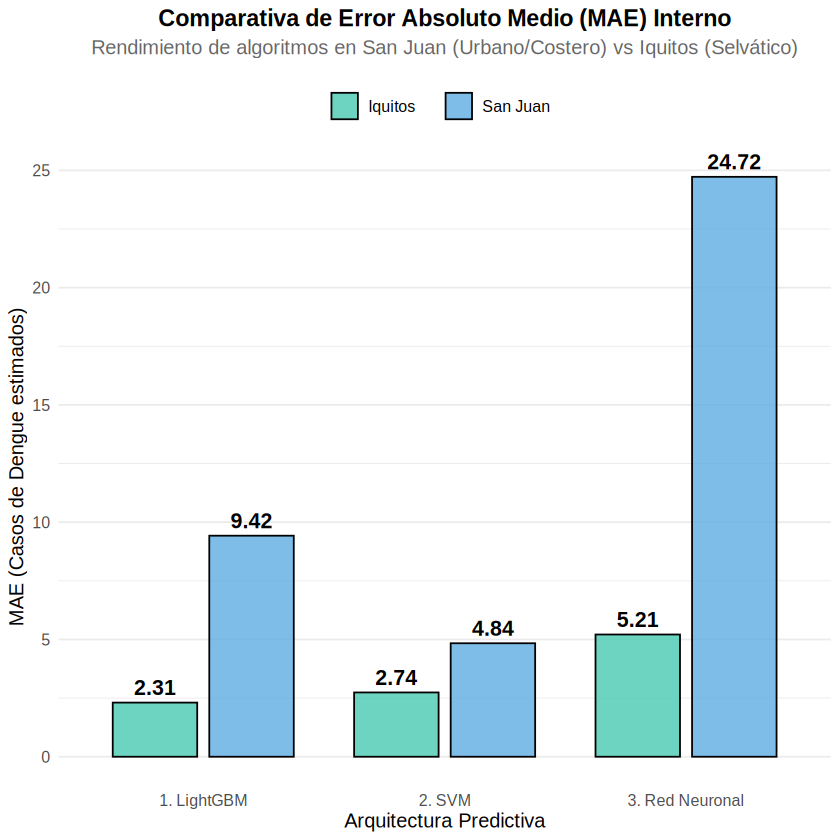

In [20]:
# Cargar ggplot2 para la visualización
if (!require("ggplot2")) install.packages("ggplot2")
library(ggplot2)

# 1. Recopilar los MAEs calculados previamente en el entorno de trabajo
mae_lgb_sj <- mean(abs(train_sj$total_cases - predict(modelo_sj, as.matrix(train_sj[, ..features_lgb]))))
mae_lgb_iq <- mean(abs(train_iq$total_cases - predict(modelo_iq, as.matrix(train_iq[, ..features_lgb]))))

mae_svm_sj <- mean(abs(train_sj$total_cases - pred_train_svm_sj))
mae_svm_iq <- mean(abs(train_iq$total_cases - pred_train_svm_iq))

mae_nn_sj  <- mean(abs(train_sj$total_cases - pred_train_sj_real))
mae_nn_iq  <- mean(abs(train_iq$total_cases - pred_train_iq_real))

# 2. Crear un Data Frame estructurado con los resultados
df_resultados <- data.frame(
  Modelo = rep(c("1. LightGBM", "2. SVM", "3. Red Neuronal"), each = 2),
  Ciudad = rep(c("San Juan", "Iquitos"), times = 3),
  MAE = c(mae_lgb_sj, mae_lgb_iq, mae_svm_sj, mae_svm_iq, mae_nn_sj, mae_nn_iq)
)

# 3. Mostrar la tabla resumen en consola
cat("\n--- Tabla Resumen de MAE Interno ---\n")
print(df_resultados)
cat("\n")

# 4. Generar y renderizar el gráfico de barras comparativo
grafico_comparativo <- ggplot(df_resultados, aes(x = Modelo, y = MAE, fill = Ciudad)) +
  geom_bar(stat = "identity", position = position_dodge(width = 0.8), width = 0.7, color="black", alpha=0.8) +
  geom_text(aes(label = round(MAE, 2)), vjust = -0.5, position = position_dodge(width = 0.8), size = 4.5, fontface="bold") +
  labs(title = "Comparativa de Error Absoluto Medio (MAE) Interno",
       subtitle = "Rendimiento de algoritmos en San Juan (Urbano/Costero) vs Iquitos (Selvático)",
       x = "Arquitectura Predictiva",
       y = "MAE (Casos de Dengue estimados)") +
  theme_minimal() +
  scale_fill_manual(values = c("San Juan" = "#5DADE2", "Iquitos" = "#48C9B0")) +
  theme(
    text = element_text(size = 12),
    plot.title = element_text(face = "bold", hjust = 0.5, size=14),
    plot.subtitle = element_text(hjust = 0.5, color = "gray40", margin=margin(b=15)),
    legend.position = "top",
    legend.title = element_blank(),
    panel.grid.major.x = element_blank()
  )

# Imprimir gráfico en el notebook
print(grafico_comparativo)